# BERT vs PubMedBERT on PubMedQA

**Course:** Natural Language Processing (S1-26_AIMLZG530)  
**Assignment 2, Set 8, Group 75**

| Name | BITS ID |
|---|---|
| Shekhar Aggarwal | 2025AG05925 |
| Asutosh Kumar | 2025AG05453 |
| Shashank | 2025AG05459 |
| Ansh Handa | 2025AG05735 |

- **Task:** BERT variant comparison (general-domain BERT vs domain-specific BERT)
- **Dataset:** PubMedQA, `pqa_labeled` subset (1000 expert-labelled questions)
- **Models:** `bert-base-uncased` and `microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract`
- **Metrics:** Accuracy, Precision, Recall, F1

PubMedQA gives a research question (usually taken from the title of a PubMed paper) and the
abstract of that paper without its conclusion. The model has to answer **yes / no / maybe**.
We treat it as 3-class sequence-pair classification: the question is segment A and the abstract
text is segment B.

Both models are BERT-base with the same architecture (12 layers, 768 hidden, 110M params). The
difference is the pretraining data and vocabulary. BERT was trained on Wikipedia + BookCorpus,
while PubMedBERT was trained from scratch on PubMed abstracts and has its own WordPiece vocab built
from that text. So any gap between them comes from the domain of pretraining, which is what this
assignment wants us to look at.

Contents
1. Setup
2. Dataset loading
3. Preprocessing and tokenization
4. Model loading and fine-tuning
5. Evaluation
6. Predictions on custom examples
7. Error analysis
8. Conclusion

## 1. Setup

In [1]:
# !pip install -q transformers datasets accelerate scikit-learn pandas matplotlib seaborn

import ast
import gc
import json
import os
import shutil
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import DatasetDict, load_dataset
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from transformers import (AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding,
                          Trainer, TrainingArguments, pipeline, set_seed)
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()
pd.set_option("display.max_colwidth", 120)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"   # we ran this on a MacBook (Apple M5, 16GB)
else:
    device = "cpu"

import transformers, datasets
print("torch", torch.__version__, "| transformers", transformers.__version__, "| datasets", datasets.__version__)
print("device:", device)

torch 2.15.0 | transformers 5.22.1 | datasets 5.1.0
device: mps


In [2]:
MODELS = {
    "BERT": "bert-base-uncased",
    "PubMedBERT": "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract",
}
LABELS = ["yes", "no", "maybe"]
label2id = {l: i for i, l in enumerate(LABELS)}
id2label = {i: l for l, i in label2id.items()}

MAX_LEN = 512
SPLIT_SEED = 42
SEEDS = [42, 7, 2024]   # each model is trained 3 times, results reported as mean +- std

# same hyperparameters for both models so the comparison is fair
HPARAMS = dict(
    learning_rate=3e-5,
    per_device_train_batch_size=8,
    gradient_accumulation_steps=2,   # effective batch size 16 (16 at once ran out of memory on our laptop)
    per_device_eval_batch_size=16,
    num_train_epochs=10,
    warmup_steps=0.1,     # in transformers 5 a float < 1 here means warmup ratio
    weight_decay=0.01,
)

OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Dataset loading

The `pubmed_qa` dataset on the Hugging Face Hub has moved to `qiaojin/PubMedQA` (the old name was a
script-based loader; with the `datasets` version we used, `load_dataset("pubmed_qa", ...)` fails because repo ids now need a namespace). The data is the same.
It has three configs:

- `pqa_labeled`: 1k questions labelled by experts (yes/no/maybe)
- `pqa_unlabeled`: 61k without labels
- `pqa_artificial`: 211k labelled automatically by a heuristic (yes/no only)

We use `pqa_labeled` because it is the only one with human labels and the "maybe" class.

In [3]:
raw = load_dataset("qiaojin/PubMedQA", "pqa_labeled")
print(raw)
raw["train"].features

DatasetDict({
    train: Dataset({
        features: ['pubid', 'question', 'context', 'long_answer', 'final_decision'],
        num_rows: 1000
    })
})


{'pubid': Value('int32'),
 'question': Value('string'),
 'context': {'contexts': List(Value('string')),
  'labels': List(Value('string')),
  'meshes': List(Value('string')),
  'reasoning_required_pred': List(Value('string')),
  'reasoning_free_pred': List(Value('string'))},
 'long_answer': Value('string'),
 'final_decision': Value('string')}

In [4]:
ex = raw["train"][0]
print("Question:", ex["question"])
print("Answer  :", ex["final_decision"])
print("Sections:", ex["context"]["labels"])
print("Context :", ex["context"]["contexts"][0][:400], "...")
print("Long answer (NOT used as input):", ex["long_answer"][:300])

Question: Do mitochondria play a role in remodelling lace plant leaves during programmed cell death?
Answer  : yes
Sections: ['BACKGROUND', 'RESULTS']
Context : Programmed cell death (PCD) is the regulated death of cells within an organism. The lace plant (Aponogeton madagascariensis) produces perforations in its leaves through PCD. The leaves of the plant consist of a latticework of longitudinal and transverse veins enclosing areoles. PCD occurs in the cells at the center of these areoles and progresses outwards, stopping approximately five cells from th ...
Long answer (NOT used as input): Results depicted mitochondrial dynamics in vivo as PCD progresses within the lace plant, and highlight the correlation of this organelle with other organelles during developmental PCD. To the best of our knowledge, this is the first report of mitochondria and chloroplasts moving on transvacuolar str


final_decision
yes      552
no       338
maybe    110

majority class share: 0.552


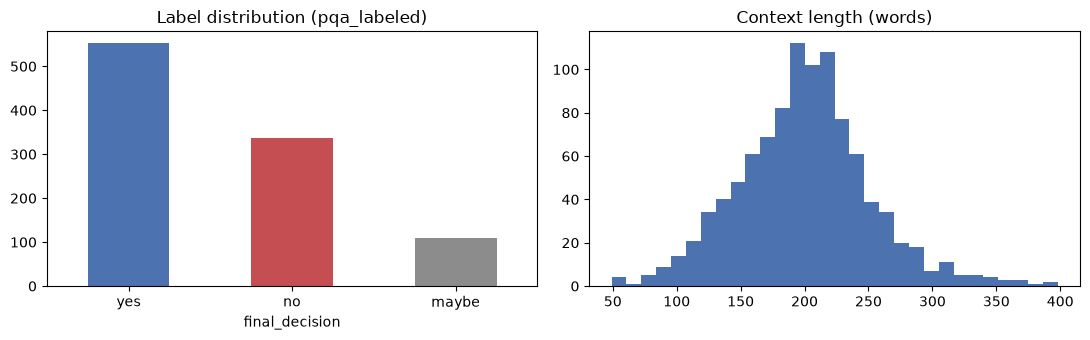

In [5]:
df = raw["train"].to_pandas()
df["contexts"] = df["context"].apply(lambda c: list(c["contexts"]))
df["n_words"] = df["contexts"].apply(lambda c: len(" ".join(c).split()))

counts = df["final_decision"].value_counts().reindex(LABELS)
print(counts.to_string())
print("\nmajority class share: %.3f" % (counts.max() / counts.sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
counts.plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52", "#8C8C8C"], rot=0)
ax[0].set_title("Label distribution (pqa_labeled)")
ax[1].hist(df["n_words"], bins=30, color="#4C72B0")
ax[1].set_title("Context length (words)")
plt.tight_layout()
plt.show()

The labels are imbalanced: about 55% yes, 34% no and only 11% maybe. A model that always says
"yes" already gets ~0.55 accuracy, so accuracy alone can be misleading here. We report macro-F1
as the main metric and also keep a majority-class baseline in the results table.

**Important:** each row also has a `long_answer` field, which is the conclusion of the abstract.
It basically states the answer ("...these results suggest that X does not ..."), so using it as
input would leak the label. We only use `question` + `context.contexts`. This matches the
"reasoning-required" setting from the PubMedQA paper.

## 3. Preprocessing and tokenization

Steps:
1. Join the abstract sections into one passage (the section titles like BACKGROUND/RESULTS are dropped).
2. Map labels to ids.
3. Make a stratified 70 / 10 / 20 split (train / validation / test). The split is made once with a
   fixed seed, and both models use exactly the same split.
4. Tokenize as a sentence pair `[CLS] question [SEP] context [SEP]`. If the pair is longer than 512
   tokens, only the context gets truncated (`truncation="only_second"`), so the question is never cut.

All inputs are padded to 512 inside the data collator. We first tried dynamic padding (pad to the
longest example in the batch), but on Apple MPS the changing tensor shapes made memory use grow
until the laptop started swapping and each step took ~30 s instead of ~2 s. Fixed-size batches fixed it.

In [6]:
def to_features(example):
    ctx = example["context"]["contexts"]
    if isinstance(ctx, str):        # just in case some version stores it as a string
        ctx = ast.literal_eval(ctx)
    return {
        "question": example["question"],
        "passage": " ".join(c.strip() for c in ctx),
        "label": label2id[example["final_decision"]],
        "pubid": example["pubid"],
    }

data = raw["train"].map(to_features, remove_columns=raw["train"].column_names)
data = data.class_encode_column("label")   # needed for stratify_by_column

tmp = data.train_test_split(test_size=0.2, stratify_by_column="label", seed=SPLIT_SEED)
tmp2 = tmp["train"].train_test_split(test_size=0.125, stratify_by_column="label", seed=SPLIT_SEED)
splits = DatasetDict(train=tmp2["train"], validation=tmp2["test"], test=tmp["test"])

for name, part in splits.items():
    c = Counter(part["label"])
    print(f"{name:<11} n={len(part):<4}", {id2label[k]: c[k] for k in range(3)})

train       n=700  {'yes': 387, 'no': 236, 'maybe': 77}
validation  n=100  {'yes': 55, 'no': 34, 'maybe': 11}
test        n=200  {'yes': 110, 'no': 68, 'maybe': 22}


### Tokenizer comparison

Before training, it is worth looking at how each tokenizer handles biomedical words. BERT's vocab
comes from Wikipedia/books, so medical terms get split into many small pieces. PubMedBERT's vocab
was built on PubMed text, so most of these terms are single tokens.

In [7]:
tokenizers = {name: AutoTokenizer.from_pretrained(path) for name, path in MODELS.items()}

sample = "Does metformin reduce the risk of hepatocellular carcinoma in diabetic patients with cirrhosis?"
for name, tok in tokenizers.items():
    pieces = tok.tokenize(sample)
    print(f"{name} ({len(pieces)} tokens): {pieces}\n")

terms = ["laparoscopic", "cholecystectomy", "thrombocytopenia", "angiography", "glycated",
         "hemoglobin", "pneumothorax", "myocardial", "infarction", "chemotherapy", "osteoporosis",
         "intraoperative", "comorbidities", "pancreatitis", "stent"]
pd.DataFrame({name: [" ".join(tok.tokenize(t)) for t in terms] for name, tok in tokenizers.items()}, index=terms)

BERT (25 tokens): ['does', 'met', '##form', '##in', 'reduce', 'the', 'risk', 'of', 'he', '##pa', '##to', '##cellular', 'car', '##cino', '##ma', 'in', 'dia', '##bet', '##ic', 'patients', 'with', 'ci', '##rr', '##hosis', '?']

PubMedBERT (14 tokens): ['does', 'metformin', 'reduce', 'the', 'risk', 'of', 'hepatocellular', 'carcinoma', 'in', 'diabetic', 'patients', 'with', 'cirrhosis', '?']



,BERT,PubMedBERT
laparoscopic,lap ##aro ##scopic,laparoscopic
cholecystectomy,cho ##le ##cy ##ste ##ct ##omy,cholecystectomy
thrombocytopenia,th ##rom ##bo ##cy ##top ##enia,thrombocytopenia
angiography,ang ##iography,angiography
glycated,g ##ly ##cated,glycated
hemoglobin,hem ##og ##lo ##bin,hemoglobin
pneumothorax,p ##ne ##um ##otho ##ra ##x,pneumothorax
myocardial,my ##oca ##rdial,myocardial
infarction,in ##far ##ction,infarction
chemotherapy,chemotherapy,chemotherapy


In [8]:
# how fragmented is the whole dataset under each tokenizer?
all_text = [q + " " + p for q, p in zip(data["question"], data["passage"])]
n_words = sum(len(t.split()) for t in all_text)

frag_rows = []
for name, tok in tokenizers.items():
    lens = np.array([len(tok(q, p)["input_ids"]) for q, p in zip(data["question"], data["passage"])])
    n_tokens = sum(len(tok.tokenize(t)) for t in all_text)
    frag_rows.append({
        "tokenizer": name,
        "vocab size": tok.vocab_size,
        "tokens per word": round(n_tokens / n_words, 3),
        "median pair length": int(np.median(lens)),
        "95th pct length": int(np.percentile(lens, 95)),
        "% truncated at 512": round(100 * (lens > MAX_LEN).mean(), 1),
    })
frag_df = pd.DataFrame(frag_rows).set_index("tokenizer")
frag_df

,vocab size,tokens per word,median pair length,95th pct length,% truncated at 512
tokenizer,,,,,
BERT,30522,1.534,326,490,3.3
PubMedBERT,28895,1.368,292,435,1.4


PubMedBERT needs about 10% fewer tokens for the same text, and fewer examples hit the 512 limit, so
it sees slightly more of the abstract. Also, a word like "hepatocellular" is one token for
PubMedBERT, which means it has one embedding learned in pretraining. BERT has to build the meaning
from pieces like `he ##pa ##to ##cellular`.

In [9]:
def tokenize_for(tok):
    def fn(batch):
        return tok(batch["question"], batch["passage"], truncation="only_second", max_length=MAX_LEN)
    return fn

encoded = {
    name: splits.map(tokenize_for(tok), batched=True, remove_columns=["question", "passage", "pubid"])
    for name, tok in tokenizers.items()
}
encoded["PubMedBERT"]["train"]

Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 700
})

In [10]:
# quick sanity check: decode one encoded example
e = encoded["PubMedBERT"]["train"][0]
print(len(e["input_ids"]), "tokens, label =", id2label[e["label"]])
print(tokenizers["PubMedBERT"].decode(e["input_ids"])[:500])

437 tokens, label = yes
[CLS] is alveolar macrophage phagocytic dysfunction in children with protracted bacterial bronchitis a forerunner to bronchiectasis? [SEP] children with recurrent protracted bacterial bronchitis ( pbb ) and bronchiectasis share common features, and pbb is likely a forerunner to bronchiectasis. both diseases are associated with neutrophilic inflammation and frequent isolation of potentially pathogenic microorganisms, including nontypeable haemophilus influenzae ( nthi ), from the lower airway. de


## 4. Model loading and fine-tuning

Both models are loaded with `AutoModelForSequenceClassification`. This puts a new linear layer
(768 -> 3) on top of the `[CLS]` output; the layer starts random and is trained with the rest of the model.

Training details (identical for both models):
- AdamW, lr 3e-5, linear decay with 10% warmup, weight decay 0.01, effective batch size 16 (8 x 2 accumulation steps)
- 10 epochs, evaluate on validation after every epoch, and keep the checkpoint with the best
  **validation macro-F1** (not lowest loss / best accuracy, because those can favour the "always yes"
  behaviour). We don't use early stopping: the validation set has only 100 examples, so its F1 jumps
  around between epochs and early stopping could end a run too soon.
- **class-weighted cross-entropy**: weights are inversely proportional to class frequency in the
  training set, so that mistakes on the small "maybe" class (11%) cost more.
- 3 random seeds per model. The training set is small (700 examples), so results change a fair
  bit from seed to seed, and one run could give a misleading comparison.

In [11]:
train_labels = np.array(splits["train"]["label"])
class_counts = np.bincount(train_labels, minlength=3)
class_weights = torch.tensor(len(train_labels) / (3 * class_counts), dtype=torch.float)
print("train counts :", dict(zip(LABELS, class_counts)))
print("class weights:", dict(zip(LABELS, class_weights.numpy().round(3))))


class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross entropy."""

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # our loss is a plain mean over the batch, so the Trainer has to divide it by the number of
        # gradient accumulation steps itself. Without this flag it assumes the model already did that
        # (BertForSequenceClassification.forward takes **kwargs) and the logged loss comes out 2x too big.
        self.model_accepts_loss_kwargs = False

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(outputs.logits.device))
        loss = loss_fn(outputs.logits, labels)
        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = logits.argmax(-1)
    p_m, r_m, f_m, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    p_w, r_w, f_w, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": p_m, "recall_macro": r_m, "f1_macro": f_m,
        "precision_weighted": p_w, "recall_weighted": r_w, "f1_weighted": f_w,
    }

train counts : {'yes': np.int64(387), 'no': np.int64(236), 'maybe': np.int64(77)}
class weights: {'yes': np.float32(0.603), 'no': np.float32(0.989), 'maybe': np.float32(3.03)}


In [12]:
def train_one(model_name, seed):
    path = MODELS[model_name]
    tok = tokenizers[model_name]
    ds = encoded[model_name]
    run_dir = f"{OUT_DIR}/ckpt_{model_name}_{seed}"

    set_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained(
        path, num_labels=len(LABELS), id2label=id2label, label2id=label2id)

    args = TrainingArguments(
        output_dir=run_dir,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="f1_macro",
        greater_is_better=True,
        logging_strategy="epoch",
        report_to="none",
        seed=seed,
        **HPARAMS,
    )
    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=ds["train"],
        eval_dataset=ds["validation"],
        data_collator=DataCollatorWithPadding(tok, padding="max_length", max_length=MAX_LEN),
        compute_metrics=compute_metrics,
    )

    start = time.time()
    trainer.train()
    minutes = (time.time() - start) / 60

    # per-epoch validation curve, for plotting later (taken before the extra evaluate() call below)
    history = [h for h in trainer.state.log_history if "eval_f1_macro" in h]

    val = trainer.evaluate(ds["validation"])   # this is the best checkpoint, reloaded at the end of training
    test_out = trainer.predict(ds["test"])
    probs = torch.softmax(torch.tensor(test_out.predictions), -1).numpy()

    return trainer, {
        "model": model_name,
        "seed": seed,
        "best_epoch": min(history, key=lambda h: -h["eval_f1_macro"])["epoch"],
        "epochs_run": history[-1]["epoch"],
        "minutes": round(minutes, 1),
        "val_f1_macro": val["eval_f1_macro"],
        **{k.replace("test_", ""): v for k, v in test_out.metrics.items() if k.startswith("test_")
           and not k.endswith(("runtime", "per_second", "loss"))},
    }, probs, history

Training loop. For every run, the test-set probabilities are saved so the later analysis can use
them without retraining. For each model we also keep the run with the best **validation** macro-F1 (the test
set is not used to pick it) and save it to `outputs/best_<model>` for the custom-example
predictions. Results, histories and probabilities are written to `outputs/` after every run. If the notebook is
re-run, finished runs are loaded from disk instead of being trained again (training all 6 runs takes
over an hour on our laptop).

In [13]:
results, histories = [], {}
best_val = {}

done = {}
if os.path.exists(f"{OUT_DIR}/results_per_run.csv"):
    for r in pd.read_csv(f"{OUT_DIR}/results_per_run.csv").to_dict("records"):
        done[(r["model"], r["seed"])] = r
if os.path.exists(f"{OUT_DIR}/best_seeds_partial.json"):
    best_val = {k: tuple(v) for k, v in json.load(open(f"{OUT_DIR}/best_seeds_partial.json")).items()}

for model_name in MODELS:
    for seed in SEEDS:
        if (model_name, seed) in done:
            print(f"==> {model_name}  seed={seed}  (already trained, loading saved results)")
            results.append(done[(model_name, seed)])
            histories[(model_name, seed)] = json.load(open(f"{OUT_DIR}/history_{model_name}_{seed}.json"))
            continue

        print(f"==> {model_name}  seed={seed}")
        trainer, row, probs, hist = train_one(model_name, seed)
        results.append(row)
        histories[(model_name, seed)] = hist
        np.save(f"{OUT_DIR}/test_probs_{model_name}_{seed}.npy", probs)
        json.dump(hist, open(f"{OUT_DIR}/history_{model_name}_{seed}.json", "w"))
        pd.DataFrame(results).to_csv(f"{OUT_DIR}/results_per_run.csv", index=False)
        print(f"    best epoch {row['best_epoch']:.0f} | val F1 {row['val_f1_macro']:.3f} | "
              f"test acc {row['accuracy']:.3f} | test macro-F1 {row['f1_macro']:.3f} | {row['minutes']} min")

        if row["val_f1_macro"] > best_val.get(model_name, (-1, None))[0]:
            best_val[model_name] = (row["val_f1_macro"], seed)
            trainer.save_model(f"{OUT_DIR}/best_{model_name}")
            tokenizers[model_name].save_pretrained(f"{OUT_DIR}/best_{model_name}")
            json.dump(best_val, open(f"{OUT_DIR}/best_seeds_partial.json", "w"))

        # free memory + disk before the next run
        shutil.rmtree(f"{OUT_DIR}/ckpt_{model_name}_{seed}", ignore_errors=True)
        del trainer
        gc.collect()
        if device == "mps":
            torch.mps.empty_cache()
        elif device == "cuda":
            torch.cuda.empty_cache()

with open(f"{OUT_DIR}/best_seeds.json", "w") as f:
    json.dump({k: v[1] for k, v in best_val.items()}, f)
print("best seed per model (by val macro-F1):", {k: v[1] for k, v in best_val.items()})

==> BERT  seed=42


    best epoch 7 | val F1 0.523 | test acc 0.400 | test macro-F1 0.315 | 15.1 min


==> BERT  seed=7


    best epoch 8 | val F1 0.469 | test acc 0.520 | test macro-F1 0.446 | 15.3 min


==> BERT  seed=2024


    best epoch 8 | val F1 0.464 | test acc 0.570 | test macro-F1 0.411 | 15.3 min
==> PubMedBERT  seed=42


... (2 outputs left out)

    best epoch 7 | val F1 0.418 | test acc 0.495 | test macro-F1 0.431 | 15.2 min


==> PubMedBERT  seed=2024


    best epoch 10 | val F1 0.509 | test acc 0.675 | test macro-F1 0.495 | 15.3 min


best seed per model (by val macro-F1): {'BERT': 42, 'PubMedBERT': 2024}


## 5. Evaluation

### 5.1 Overall results on the test set (200 examples)

Macro averages give each class equal weight, so "maybe" counts as much as "yes". Weighted
averages weight each class by how many test examples it has. Both are shown.

In [14]:
res = pd.DataFrame(results)
res.round(4)

,model,seed,best_epoch,epochs_run,minutes,val_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
0,BERT,42,7.0,10.0,15.1,0.5226,0.400,0.3209,0.3153,0.3145,0.4218,0.400,0.4065
1,BERT,7,8.0,10.0,15.3,0.4695,0.520,0.4664,0.4394,0.4461,0.5274,0.520,0.5199
2,BERT,2024,8.0,10.0,15.3,0.4643,0.570,0.4468,0.4127,0.4107,0.5369,0.570,0.5356
3,PubMedBERT,42,10.0,10.0,15.4,0.4805,0.645,0.4346,0.4920,0.4567,0.5977,0.645,0.6144
4,PubMedBERT,7,7.0,10.0,15.2,0.4178,0.495,0.4303,0.4401,0.4313,0.5174,0.495,0.5016
5,PubMedBERT,2024,10.0,10.0,15.3,0.5089,0.675,0.6096,0.5111,0.4955,0.6598,0.675,0.6446


In [15]:
metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro",
               "precision_weighted", "recall_weighted", "f1_weighted"]

y_test = np.array(splits["test"]["label"])
maj = np.full_like(y_test, label2id["yes"])
maj_row = compute_metrics((np.eye(3)[maj], y_test))

summary = res.groupby("model")[metric_cols].agg(["mean", "std"])
table = pd.DataFrame({
    m: [f"{summary.loc[m, (c, 'mean')]:.3f} ± {summary.loc[m, (c, 'std')]:.3f}" for c in metric_cols]
    for m in MODELS
}, index=metric_cols).T
table.loc["Majority class (always 'yes')"] = [f"{maj_row[c]:.3f}" for c in metric_cols]
table

,accuracy,precision_macro,recall_macro,f1_macro,precision_weighted,recall_weighted,f1_weighted
BERT,0.497 ± 0.087,0.411 ± 0.079,0.389 ± 0.065,0.390 ± 0.068,0.495 ± 0.064,0.497 ± 0.087,0.487 ± 0.070
PubMedBERT,0.605 ± 0.096,0.491 ± 0.102,0.481 ± 0.037,0.461 ± 0.032,0.592 ± 0.071,0.605 ± 0.096,0.587 ± 0.075
Majority class (always 'yes'),0.550,0.183,0.333,0.237,0.303,0.550,0.390


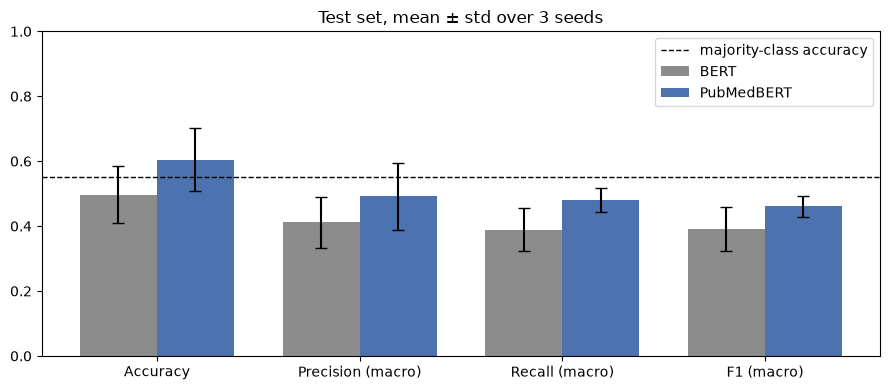

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
main = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]
x = np.arange(len(main))
for i, (m, color) in enumerate(zip(MODELS, ["#8C8C8C", "#4C72B0"])):
    means = [summary.loc[m, (c, "mean")] for c in main]
    stds = [summary.loc[m, (c, "std")] for c in main]
    ax.bar(x + (i - 0.5) * 0.38, means, 0.38, yerr=stds, capsize=4, label=m, color=color)
ax.axhline(maj_row["accuracy"], ls="--", c="k", lw=1, label="majority-class accuracy")
ax.set_xticks(x)
ax.set_xticklabels(["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"])
ax.set_ylim(0, 1)
ax.set_title("Test set, mean ± std over 3 seeds")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [17]:
# paired comparison: same seed, same split, only the model changes
paired = res.pivot(index="seed", columns="model", values=["accuracy", "f1_macro"])
for metric in ["accuracy", "f1_macro"]:
    diff = paired[(metric, "PubMedBERT")] - paired[(metric, "BERT")]
    print(f"{metric:<9} PubMedBERT - BERT per seed: {diff.round(3).tolist()}  mean = {diff.mean():+.3f}")

accuracy  PubMedBERT - BERT per seed: [-0.025, 0.245, 0.105]  mean = +0.108
f1_macro  PubMedBERT - BERT per seed: [-0.015, 0.142, 0.085]  mean = +0.071


**Observations**

- PubMedBERT is better on average on all four metrics: +0.108 accuracy and +0.071 macro-F1 over BERT.
- It wins on 2 of the 3 seeds. On seed 7 BERT is slightly ahead (0.446 vs 0.431 macro-F1, 0.520 vs 0.495 accuracy), so the domain model is not better in every single run.
- Results vary a lot between seeds (BERT accuracy ranges from 0.40 to 0.57). That is expected with only 700 training examples. Gu et al. (2020) also mention high variance between seeds on PubMedQA, and they average 10 runs for it.
- On accuracy, only PubMedBERT beats the majority-class baseline on average (0.605 vs 0.550). BERT averages 0.497. Part of the reason is probably the class weights: they push the model away from answering "yes" all the time. That costs some accuracy but helps macro-F1, where both models are well above the baseline (0.237).
- For reference, Gu et al. (2020, Table 6) report 51.62 accuracy for BERT-uncased and 55.84 for PubMedBERT on PubMedQA. Their setup is different (450 train / 500 test, 10 seeds, tuned hyperparameters), so the numbers can't be compared directly, but the direction is the same.

### 5.2 Validation curves

Validation macro-F1 after each epoch. This shows how fast each model learns and where early stopping kicked in.

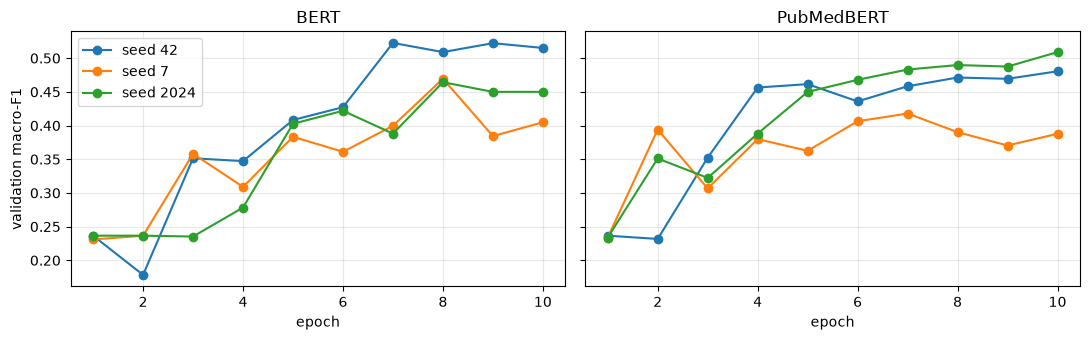

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, m in zip(axes, MODELS):
    for s in SEEDS:
        h = histories[(m, s)]
        ax.plot([e["epoch"] for e in h], [e["eval_f1_macro"] for e in h], marker="o", label=f"seed {s}")
    ax.set_title(m)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("validation macro-F1")
axes[0].legend()
plt.tight_layout()
plt.show()

BERT reached its best validation score at epoch 7-8 in all three runs. PubMedBERT peaked at epoch 10
in two of three runs, so it might still have improved with more epochs. We kept 10 epochs for both models
so they get the same training budget.

One thing to note: on the validation set the two models are about equal (mean best validation F1 is 0.485
for BERT and 0.469 for PubMedBERT), while on the test set PubMedBERT is clearly ahead. With only 100
validation examples, a few questions can change the ranking, so we trust the 200-example test set more
for the comparison. Validation was only used to pick the checkpoint inside each run.

### 5.3 Per-class results

Single runs are noisy (see the table above), so for the per-class results and for the error analysis in
section 7 we average the test-set probabilities of the 3 seeds of each model and take the argmax. This is a
small ensemble, and it shows the typical behaviour of each model better than any one seed does.

In [19]:
best_seeds = {k: v[1] for k, v in best_val.items()}
test_probs = {m: {s: np.load(f"{OUT_DIR}/test_probs_{m}_{s}.npy") for s in SEEDS} for m in MODELS}
avg_probs = {m: np.mean([test_probs[m][s] for s in SEEDS], axis=0) for m in MODELS}
test_pred = {m: avg_probs[m].argmax(-1) for m in MODELS}

for m in MODELS:
    print(f"===== {m} (average of 3 seeds) =====")
    print(classification_report(y_test, test_pred[m], target_names=LABELS, digits=3, zero_division=0))

===== BERT (average of 3 seeds) =====
              precision    recall  f1-score   support

         yes      0.626     0.700     0.661       110
          no      0.452     0.412     0.431        68
       maybe      0.333     0.227     0.270        22

    accuracy                          0.550       200
   macro avg      0.470     0.446     0.454       200
weighted avg      0.535     0.550     0.540       200

===== PubMedBERT (average of 3 seeds) =====
              precision    recall  f1-score   support

         yes      0.734     0.727     0.731       110
          no      0.616     0.779     0.688        68
       maybe      0.200     0.045     0.074        22

    accuracy                          0.670       200
   macro avg      0.517     0.517     0.498       200
weighted avg      0.635     0.670     0.644       200



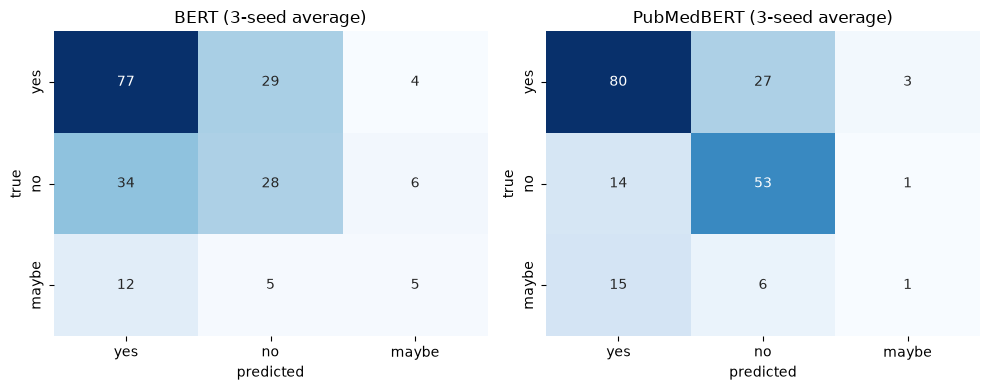

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, m in zip(axes, MODELS):
    cm = confusion_matrix(y_test, test_pred[m], labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=LABELS, yticklabels=LABELS)
    ax.set_title(f"{m} (3-seed average)")
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
plt.tight_layout()
plt.show()

**Observations**

- The biggest difference is on the **"no"** class: F1 0.688 for PubMedBERT vs 0.431 for BERT. The
  confusion matrices show that BERT often answers "yes" when the answer is "no" (34 test questions vs
  14 for PubMedBERT).
- PubMedBERT is also better on "yes" (F1 0.731 vs 0.661).
- **"maybe"** is the weak point for both. PubMedBERT almost never predicts it (1 of 22 correct), BERT gets
  5 of 22. So even with class weighting, the domain model learned to commit to yes or no. "maybe" is the
  only class where BERT does better.
- The averaged models score 0.670 (PubMedBERT) and 0.550 (BERT) accuracy, higher than the average single run
  of each model, which is normal for an ensemble.

## 6. Predictions on custom examples

We wrote 6 short question + abstract pairs ourselves (they are made up, not taken from PubMed) to see how
the fine-tuned models behave on new input. They cover a clear yes, a clear no, an uncertain finding
that should be "maybe", a negated result, a mixed result, and one non-medical example to see what
happens outside the training domain.

We use the `text-classification` pipeline with the saved best model of each type. The pipeline accepts a
`{"text": ..., "text_pair": ...}` dict, so the input is encoded the same way as in training.

In [21]:
custom = [
    {
        "question": "Does regular aerobic exercise lower blood pressure in adults with hypertension?",
        "context": "We randomised 240 adults with stage 1 hypertension to a 12-week supervised aerobic exercise "
                   "programme or usual care. Ambulatory blood pressure was measured at baseline and at 12 weeks. "
                   "Systolic blood pressure decreased by 8.1 mmHg in the exercise group compared with 1.2 mmHg in "
                   "the control group (p<0.001). Diastolic pressure also fell significantly. Adherence was 86%.",
        "expected": "yes",
    },
    {
        "question": "Does vitamin C supplementation prevent the common cold in healthy adults?",
        "context": "A total of 1,150 healthy adults received 1 g of vitamin C or placebo daily during the winter season. "
                   "The incidence of colds was 41% in the vitamin C group and 43% in the placebo group, which was not "
                   "statistically significant (p=0.52). Duration and severity of symptoms did not differ between groups.",
        "expected": "no",
    },
    {
        "question": "Is coffee consumption associated with a lower risk of Parkinson's disease?",
        "context": "In this cohort of 8,400 participants followed for 14 years, 112 developed Parkinson's disease. "
                   "Higher coffee intake was associated with a lower risk in men (HR 0.71, 95% CI 0.49-1.02) but not in "
                   "women. After adjustment for smoking the association was weaker. The number of cases was small and "
                   "residual confounding cannot be excluded.",
        "expected": "maybe",
    },
    {
        "question": "Do statins increase the risk of cancer in elderly patients?",
        "context": "We analysed 21,000 patients aged over 70 years, of whom 9,800 were prescribed statins. During a median "
                   "follow-up of 6 years, cancer incidence was 14.2% among statin users and 14.6% among non-users. "
                   "No increase in overall cancer or in any specific cancer type was observed with statin use.",
        "expected": "no",
    },
    {
        "question": "Is laparoscopic appendectomy associated with a shorter hospital stay than open appendectomy?",
        "context": "Records of 530 patients undergoing appendectomy between 2015 and 2020 were reviewed. Mean hospital stay "
                   "was 2.1 days after laparoscopic and 3.4 days after open surgery (p<0.01). Intra-abdominal abscess was "
                   "slightly more frequent in the laparoscopic group, although the difference was not significant.",
        "expected": "yes",
    },
    {
        "question": "Did the new traffic signal timing reduce accidents at city intersections?",
        "context": "The city changed signal timing at 40 intersections in 2019. Accident reports for two years before and "
                   "after the change were compared with 40 similar intersections where timing was not changed. Accidents "
                   "fell by 22% at the modified intersections and by 3% at the comparison sites.",
        "expected": "yes",
    },
]

pipes = {
    m: pipeline("text-classification", model=f"{OUT_DIR}/best_{m}", tokenizer=f"{OUT_DIR}/best_{m}",
                device=device, top_k=None, truncation=True, max_length=MAX_LEN)
    for m in MODELS
}

inputs = [{"text": c["question"], "text_pair": c["context"]} for c in custom]
custom_rows = []
for m, pipe in pipes.items():
    outs = pipe(inputs)
    for c, out in zip(custom, outs):
        scores = {d["label"]: d["score"] for d in out}
        custom_rows.append({
            "question": c["question"], "expected": c["expected"], "model": m,
            "predicted": max(scores, key=scores.get),
            **{f"p({l})": round(scores[l], 3) for l in LABELS},
        })

custom_df = pd.DataFrame(custom_rows)
custom_df

,question,expected,model,predicted,p(yes),p(no),p(maybe)
0,Does regular aerobic exercise lower blood pressure in adults with hypertension?,yes,BERT,maybe,0.004,0.004,0.991
1,Does vitamin C supplementation prevent the common cold in healthy adults?,no,BERT,no,0.053,0.911,0.036
2,Is coffee consumption associated with a lower risk of Parkinson's disease?,maybe,BERT,no,0.014,0.967,0.019
3,Do statins increase the risk of cancer in elderly patients?,no,BERT,no,0.018,0.944,0.038
4,Is laparoscopic appendectomy associated with a shorter hospital stay than open appendectomy?,yes,BERT,no,0.023,0.714,0.263
5,Did the new traffic signal timing reduce accidents at city intersections?,yes,BERT,maybe,0.045,0.177,0.778
6,Does regular aerobic exercise lower blood pressure in adults with hypertension?,yes,PubMedBERT,yes,0.994,0.004,0.002
7,Does vitamin C supplementation prevent the common cold in healthy adults?,no,PubMedBERT,no,0.001,0.998,0.001
8,Is coffee consumption associated with a lower risk of Parkinson's disease?,maybe,PubMedBERT,yes,0.990,0.009,0.001
9,Do statins increase the risk of cancer in elderly patients?,no,PubMedBERT,no,0.002,0.997,0.001


In [22]:
side = custom_df.pivot(index="question", columns="model", values="predicted")
side.insert(0, "expected", custom_df.drop_duplicates("question").set_index("question")["expected"])
side = side.loc[[c["question"] for c in custom]]
print("correct:", {m: int((side[m] == side["expected"]).sum()) for m in MODELS}, "out of", len(side))
side

correct: {'BERT': 2, 'PubMedBERT': 5} out of 6


model,expected,BERT,PubMedBERT
question,,,
Does regular aerobic exercise lower blood pressure in adults with hypertension?,yes,maybe,yes
Does vitamin C supplementation prevent the common cold in healthy adults?,no,no,no
Is coffee consumption associated with a lower risk of Parkinson's disease?,maybe,no,yes
Do statins increase the risk of cancer in elderly patients?,no,no,no
Is laparoscopic appendectomy associated with a shorter hospital stay than open appendectomy?,yes,no,yes
Did the new traffic signal timing reduce accidents at city intersections?,yes,maybe,yes


**Observations**

PubMedBERT got 5 of 6 right, BERT got 2 of 6.

- Neither model said "maybe" for the coffee example, which we wrote to be uncertain (weak association,
  confidence interval crossing 1, possible confounding). PubMedBERT said "yes" with 0.99 probability.
  This matches the per-class results: "maybe" is hard to learn from 77 training examples, and the model
  seems to react to phrases like "associated with a lower risk".
- The laparoscopic example is almost a tie for PubMedBERT (0.507 yes vs 0.492 no). The context also
  mentions a worse outcome (more abscesses), which probably pulls it towards "no".
- BERT said "maybe" with 0.99 probability for the exercise example, even though the result there is
  clear. The saved BERT model is seed 42, which was picked because it had the best validation F1, but
  it was the weakest BERT run on the test set (accuracy 0.40). So these examples probably make BERT
  look worse than its average.
- The traffic example is not medical, but PubMedBERT still got it right. The abstract has the same
  structure as a clinical study (before/after, control group, percentages), which may be why.
- With only 6 examples this is a qualitative check, not a measurement.

## 7. Error analysis

This section looks at *where* the models go wrong, not just how often. It uses the 3-seed averaged
predictions from 5.3.

In [23]:
test_df = splits["test"].to_pandas()
test_df["gold"] = test_df["label"].map(id2label)
for m in MODELS:
    test_df[f"pred_{m}"] = [id2label[i] for i in test_pred[m]]
    test_df[f"conf_{m}"] = avg_probs[m].max(-1)
    test_df[f"ok_{m}"] = test_df[f"pred_{m}"] == test_df["gold"]
    test_df[f"len_{m}"] = [len(tokenizers[m](q, p)["input_ids"]) for q, p in zip(test_df.question, test_df.passage)]

both_ok = (test_df.ok_BERT & test_df.ok_PubMedBERT).sum()
only_pm = (~test_df.ok_BERT & test_df.ok_PubMedBERT).sum()
only_bert = (test_df.ok_BERT & ~test_df.ok_PubMedBERT).sum()
both_wrong = (~test_df.ok_BERT & ~test_df.ok_PubMedBERT).sum()
print(f"both correct      : {both_ok}")
print(f"only PubMedBERT ok: {only_pm}")
print(f"only BERT ok      : {only_bert}")
print(f"both wrong        : {both_wrong}")

both correct      : 84
only PubMedBERT ok: 50
only BERT ok      : 26
both wrong        : 40


### 7.1 Which classes get confused?

In [24]:
err_rows = []
for m in MODELS:
    wrong = test_df[~test_df[f"ok_{m}"]]
    pairs = Counter(zip(wrong.gold, wrong[f"pred_{m}"]))
    for (g, p), n in pairs.items():
        err_rows.append({"model": m, "true -> predicted": f"{g} -> {p}", "count": n})
pd.DataFrame(err_rows).pivot_table(index="true -> predicted", columns="model", values="count",
                                   fill_value=0).sort_values("PubMedBERT", ascending=False)

model,BERT,PubMedBERT
true -> predicted,,
yes -> no,29.0,27.0
maybe -> yes,12.0,15.0
no -> yes,34.0,14.0
maybe -> no,5.0,6.0
yes -> maybe,4.0,3.0
no -> maybe,6.0,1.0


### 7.2 Does input length / truncation matter?

In [25]:
rows = []
for m in MODELS:
    trunc = test_df[f"len_{m}"] > MAX_LEN
    for flag, name in [(False, "fits in 512"), (True, "truncated")]:
        part = test_df[trunc == flag]
        rows.append({"model": m, "group": name, "n": len(part), "accuracy": part[f"ok_{m}"].mean()})
    q = pd.qcut(test_df[f"len_{m}"], 4, labels=["Q1 (short)", "Q2", "Q3", "Q4 (long)"])
    for b in q.cat.categories:
        part = test_df[q == b]
        rows.append({"model": m, "group": f"length {b}", "n": len(part), "accuracy": part[f"ok_{m}"].mean()})
pd.DataFrame(rows).pivot(index="group", columns="model", values=["n", "accuracy"]).round(3)

n            accuracy           
model               BERT PubMedBERT     BERT PubMedBERT
group                                                  
fits in 512        190.0      196.0    0.542      0.663
length Q1 (short)   50.0       50.0    0.540      0.620
length Q2           50.0       51.0    0.600      0.647
length Q3           50.0       49.0    0.480      0.735
length Q4 (long)    50.0       50.0    0.580      0.680
truncated           10.0        4.0    0.700      1.000

### 7.3 Confidence of right vs wrong predictions

,mean conf (correct),mean conf (wrong),wrong with conf > 0.8
model,,,
BERT,0.732,0.703,29
PubMedBERT,0.809,0.751,24


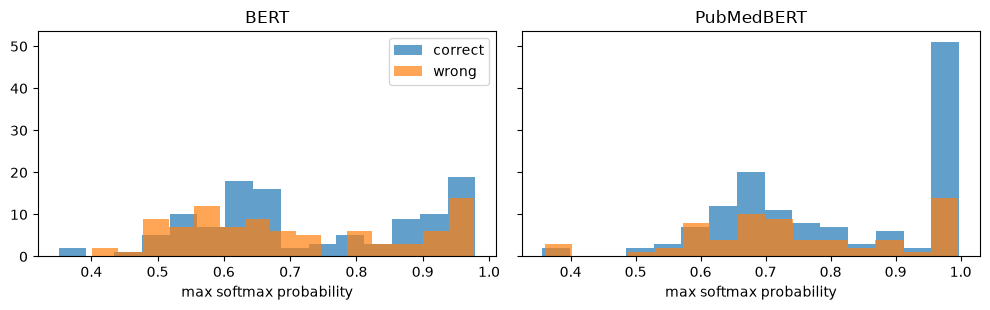

In [26]:
conf_rows = []
for m in MODELS:
    conf_rows.append({"model": m,
                      "mean conf (correct)": test_df.loc[test_df[f"ok_{m}"], f"conf_{m}"].mean(),
                      "mean conf (wrong)": test_df.loc[~test_df[f"ok_{m}"], f"conf_{m}"].mean(),
                      "wrong with conf > 0.8": int((~test_df[f"ok_{m}"] & (test_df[f"conf_{m}"] > 0.8)).sum())})
display(pd.DataFrame(conf_rows).set_index("model").round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, m in zip(axes, MODELS):
    ax.hist(test_df.loc[test_df[f"ok_{m}"], f"conf_{m}"], bins=15, alpha=0.7, label="correct")
    ax.hist(test_df.loc[~test_df[f"ok_{m}"], f"conf_{m}"], bins=15, alpha=0.7, label="wrong")
    ax.set_title(m)
    ax.set_xlabel("max softmax probability")
axes[0].legend()
plt.tight_layout()
plt.show()

### 7.4 Does domain vocabulary explain the difference?

For each test example we compute how fragmented it is under BERT's tokenizer (BERT tokens per word).
If the domain vocabulary is what helps PubMedBERT, the gap between the two models should be larger
on the more fragmented (more technical) examples.

In [27]:
test_df["bert_frag"] = [len(tokenizers["BERT"].tokenize(q + " " + p)) / len((q + " " + p).split())
                        for q, p in zip(test_df.question, test_df.passage)]
test_df["frag_bin"] = pd.qcut(test_df.bert_frag, 3, labels=["low", "medium", "high"])
frag_tab = test_df.groupby("frag_bin", observed=True).agg(
    n=("gold", "size"),
    bert_tokens_per_word=("bert_frag", "mean"),
    acc_BERT=("ok_BERT", "mean"),
    acc_PubMedBERT=("ok_PubMedBERT", "mean"),
)
frag_tab["gap"] = frag_tab.acc_PubMedBERT - frag_tab.acc_BERT
frag_tab.round(3)

,n,bert_tokens_per_word,acc_BERT,acc_PubMedBERT,gap
frag_bin,,,,,
low,67,1.332,0.522,0.627,0.104
medium,66,1.525,0.576,0.682,0.106
high,67,1.762,0.552,0.701,0.149


### 7.5 Looking at individual examples

In [28]:
def show(rows, k=3):
    for _, r in rows.head(k).iterrows():
        print(f"Q: {r.question}")
        print(f"   gold={r.gold} | BERT={r.pred_BERT} ({r.conf_BERT:.2f}) | "
              f"PubMedBERT={r.pred_PubMedBERT} ({r.conf_PubMedBERT:.2f})")
        print(f"   context end: ...{r.passage[-300:]}\n")

print("---- PubMedBERT right, BERT wrong ----\n")
show(test_df[test_df.ok_PubMedBERT & ~test_df.ok_BERT])
print("---- BERT right, PubMedBERT wrong ----\n")
show(test_df[~test_df.ok_PubMedBERT & test_df.ok_BERT])

---- PubMedBERT right, BERT wrong ----

Q: Are patients with diabetes receiving the same message from dietitians and nurses?
   gold=no | BERT=yes (0.96) | PubMedBERT=no (0.70)
   context end: ...etes. However, RDs were more likely than RNs to make recommendations for fiber intake or use of the glycemic index. A significant difference also was found in the treatment of hypoglycemia: RNs were more likely than RDs to recommend consuming a carbohydrate source with protein to treat hypoglycemia.

Q: Are WHO/UNAIDS/UNICEF-recommended replacement milks for infants of HIV-infected mothers appropriate in the South African context?
   gold=no | BERT=yes (0.96) | PubMedBERT=no (0.61)
   context end: ...xture. It took 21-25 minutes to optimally prepare 120 ml of replacement feed from PM or commercial infant formula and 30-35 minutes for the fresh milk preparation. PM or FM cost approximately 20% of monthly income averaged over the first six months of life; commercial formula cost approximately 32

In [29]:
print("---- both wrong, sorted by PubMedBERT confidence ----\n")
show(test_df[~test_df.ok_PubMedBERT & ~test_df.ok_BERT].sort_values("conf_PubMedBERT", ascending=False), k=4)

---- both wrong, sorted by PubMedBERT confidence ----

Q: Are adult body circumferences associated with height?
   gold=yes | BERT=no (0.69) | PubMedBERT=no (1.00)
   context end: ...race-adjusted incremental increases in circumferences ranged from 0.2 to 0.5 cm per centimeter increase in height. Both WC/height and HC/height scaled negatively to height in men and women, and WC/HC scaled negatively to height in women only (all P<0.001). Health status-adjusted models were similar.

Q: Sternal skin conductance: a reasonable surrogate for hot flash measurement?
   gold=no | BERT=yes (0.97) | PubMedBERT=yes (1.00)
   context end: ...ry failure. However, 16 women wore the device for 5 weeks and reported that wearing the device was acceptable, although 31% stated that it interfered with daily activities. Hot flash data from the second prototype revealed a 24% concordance rate between self-reported and device-recorded hot flashes.

Q: Xanthogranulomatous cholecystitis: a premalignant condition

In [30]:
print("---- gold = maybe ----\n")
maybe = test_df[test_df.gold == "maybe"]
print(maybe[["pred_BERT", "pred_PubMedBERT"]].apply(pd.Series.value_counts).fillna(0).astype(int), "\n")
show(maybe, k=3)

---- gold = maybe ----

       pred_BERT  pred_PubMedBERT
maybe          5                1
no             5                6
yes           12               15 

Q: Is a patient's self-reported health-related quality of life a prognostic factor for survival in non-small-cell lung cancer patients?
   gold=maybe | BERT=yes (0.98) | PubMedBERT=yes (0.96)
   context end: ...ain with HR= 1.11 (95% CI 1.07-1.16; P<0.001) and dysphagia with HR = 1.12 (95% CI 1.04-1.21; P = 0.003). A 10-point shift worse in the scale measuring pain and dysphagia translated into an 11% and 12% increased in the likelihood of death respectively. A risk group categorization was also developed.

Q: Is tumour expression of VEGF associated with venous invasion and survival in pT3 renal cell carcinoma?
   gold=maybe | BERT=maybe (0.38) | PubMedBERT=yes (0.66)
   context end: ...of the perirenal fat, lymph node involvement, distant metastases and VEGF expression were significantly associated with survival (p<0.01). On 

### 7.6 Summary of the error analysis

1. Most errors are mix-ups between yes and no. For PubMedBERT the most common error is yes -> no (27). For BERT
   it is no -> yes (34), so BERT tends to say "yes" when it is unsure, and PubMedBERT handles "no"
   much better. Out of 200 test questions, 50 are answered correctly only by PubMedBERT and 26 only by
   BERT, so BERT is not just a weaker copy of PubMedBERT; they make different mistakes.
2. "maybe" is almost never predicted correctly (BERT 5/22, PubMedBERT 1/22). Most true "maybe"
   questions are predicted as "yes". In several of them the abstract does report a significant result
   (e.g. the VEGF example), and the "maybe" comes from the authors' cautious wording in the conclusion.
   The conclusion is in `long_answer`, which the model never sees, so some of these are very hard to
   get from the input alone.
3. Input length and truncation don't seem to matter much. Accuracy does not drop for longer abstracts, and
   only 10 (BERT) / 4 (PubMedBERT) test examples were truncated at all, which is too few to say anything
   about truncation.
4. Both models are overconfident. The average confidence on wrong answers is close to the average on
   right ones (PubMedBERT 0.75 vs 0.81, BERT 0.70 vs 0.73), and PubMedBERT gives probabilities near
   1.00 on some wrong answers. So the probability is not a good signal of when the model is wrong.
5. PubMedBERT's advantage is a bit larger on the most fragmented third of the test set
   (gap 0.149 vs about 0.105 for the other two thirds). That fits the idea that the domain vocabulary
   helps with technical text, but with about 67 examples per group the difference is small and could
   easily be noise. We would not call it proven.
6. A lot of the questions both models get wrong need some reasoning over numbers. For example, in "Are adult body
   circumferences associated with height?" (gold: yes) the abstract reports small but significant
   increases per cm of height. In the hot-flash device example (gold: no), the key fact is a 24%
   concordance rate, and the model has to know that this is low. A classifier on top of the [CLS] token
   doesn't do this kind of reasoning well, especially with 700 training examples.

## 8. Conclusion

| (mean ± std over 3 seeds, test set) | Accuracy | Precision (macro) | Recall (macro) | F1 (macro) |
|---|---|---|---|---|
| bert-base-uncased | 0.497 ± 0.087 | 0.411 ± 0.079 | 0.389 ± 0.065 | 0.390 ± 0.068 |
| PubMedBERT | **0.605 ± 0.096** | **0.491 ± 0.102** | **0.481 ± 0.037** | **0.461 ± 0.032** |
| majority class | 0.550 | 0.183 | 0.333 | 0.237 |

- PubMedBERT did better than BERT on all four metrics. With the 3-seed ensemble the gap is 0.670 vs
  0.550 accuracy and 0.498 vs 0.454 macro-F1.
- Both models have the same architecture, size and fine-tuning setup, so the difference comes from
  pretraining. PubMedBERT was pretrained on the same kind of text as this task (PubMed abstracts), and
  its vocabulary fits that text better (1.37 vs 1.53 tokens per word, so many biomedical terms are single tokens
  instead of several pieces).
- The gain is not uniform. It comes from the "yes" and "no" classes. "maybe" stays very poor for both
  models, and there BERT is actually a bit better. Results also vary a lot between seeds, and on one of the
  three seeds BERT was slightly ahead. This matches what Gu et al. (2020) report for PubMedQA.
- The task is hard for both models: the best macro-F1 is below 0.5. The main reason is the small amount of
  labelled data (700 training questions), together with the fact that "maybe" often depends on
  the authors' conclusion, which is not part of the input.

**Limitations / what we would try next**

- Only 3 seeds and one data split. With 200 test examples, one question is worth 0.5% accuracy, so 5-10 seeds or
  cross-validation would give more reliable numbers.
- The 100-example validation set is noisy. The BERT run it selected (seed 42) turned out to be the weakest on the test set.
- Hyperparameters were not tuned separately per model; both used the same standard values.
- An extra fine-tuning step on the large automatically labelled `pqa_artificial` set (211k questions) before
  `pqa_labeled` would probably help with the small-data problem, but it needs more compute than we had on a laptop.

**Reference:** Gu, Y. et al. (2020). *Domain-Specific Language Model Pretraining for Biomedical Natural Language
Processing.* arXiv:2007.15779. Jin, Q. et al. (2019). *PubMedQA: A Dataset for Biomedical Research Question
Answering.* EMNLP.